# Fleet Maintenance Planning: Final Report Notebook
**CSE 343 / ECE 363 Machine Learning, IIIT Delhi, Monsoon 2026. Group project, Problem 2**

| | |
|---|---|
| Team | *Section A, Team ___: (fill in member names and roll numbers)* |
| GitHub repo | *https://github.com/<group-representative>/<repo>* (TA added as collaborator) |
| Final Kaggle submission | `sub_v3.csv`, Git tag *`sub-NN-2026-11-DD`* |

This notebook runs top to bottom from a clean kernel (about 12 minutes on 2 CPU cores). It writes the three CSVs for the selected models:

| File | Model |
|---|---|
| `sub_v1.csv` | **V1 baseline.** Logistic regression, used as a plain classifier |
| `sub_v2.csv` | **V2.** Calibrated LightGBM, plus a Bayes-optimal flag/budget decision rule, plus depot harmonisation |
| `sub_v3.csv` | **V3 (final).** V2, plus a per-vehicle repair-cost model (LightGBM + ridge blend with engineered features), censoring treatment, a LightGBM/XGBoost/CatBoost ensemble on depot-stable sensors, and a correction for the depot's failure prior |

Each section records the evidence for one of the five evaluation factors: leaderboard, gains across versions, data/error analysis, contributions, and understanding.

## 1. Problem, metric, rules

**Task.** Each test vehicle comes from a *different depot* than the training vehicles. For each one we choose
* `flag`: 1 means inspect the vehicle (costs 10),
* `budget` $b \ge 0$: value of parts pre-ordered (ignored if not flagged).

**Cost of vehicle $i$** (lower is better; the score is the sum). Here $c_i$ is the repair cost if the vehicle fails, else 0:
$$\text{cost}_i=\begin{cases}10 + 0.20\,(c_i-b_i)^+ + 0.02\,(b_i-c_i)^+ & \text{flag}_i=1\\ c_i & \text{flag}_i=0\end{cases}$$

**Rules compliance.** We use only course models: logistic regression, gradient-boosted trees (LightGBM, XGBoost, CatBoost), logistic regression again for probability calibration (Platt scaling: a 1-feature logistic regression on the model's log-odds), linear regression to re-scale the cost predictions, a two-component mixture model, and EM over a latent label. Every method appears explicitly in the competition's list of permitted models and methods. Libraries are numpy, pandas, scipy, scikit-learn, lightgbm, xgboost, catboost and matplotlib, all on the allowed list. We use no deep-learning frameworks, pre-trained models, AutoML, LLM-generated predictions, or external data. Test rows are used only unlabelled, for distribution-shift diagnostics: adversarial validation and estimating the failure prior.

In [1]:
import os, glob, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

SEED = 2024
np.random.seed(SEED)
T0 = time.time()

# paths: works on Kaggle (/kaggle/input/...) and locally (./data or ../data)
cands = sorted(glob.glob("/kaggle/input/**/train.csv", recursive=True)) + \
        [p for p in ["data/train.csv", "../data/train.csv"] if os.path.exists(p)]
DATA_DIR = os.path.dirname(cands[0])
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "submissions"
os.makedirs(OUT_DIR, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
print("data:", DATA_DIR, "| outputs:", OUT_DIR, "| lightgbm", lgb.__version__)

data: data | outputs: submissions | lightgbm 4.7.0


### 1.1 Metric implementation and unit tests
We code the exact metric and check it by hand on small cases: an under-budget repair, an over-budget order, a missed failure, an unnecessary inspection, and doing nothing.

In [2]:
INSPECT, RUSH, RETURN = 10.0, 0.20, 0.02
Q_STAR = RUSH / (RUSH + RETURN)          # = 0.90909, the optimal P(c <= b) (derived in section 6.1)

def fleet_cost(flag, budget, failure, repair_cost):
    flag = np.asarray(flag).astype(int)
    b = np.maximum(np.asarray(budget, float), 0.0)
    c = np.where(np.asarray(failure) == 1, np.nan_to_num(np.asarray(repair_cost, float)), 0.0)
    flagged = INSPECT + RUSH * np.maximum(c - b, 0) + RETURN * np.maximum(b - c, 0)
    return np.where(flag == 1, flagged, c)

assert np.isclose(fleet_cost([1], [100], [1], [300])[0], 10 + 0.2 * 200)    # under-budget -> rush
assert np.isclose(fleet_cost([1], [300], [1], [100])[0], 10 + 0.02 * 200)   # over-budget -> return
assert np.isclose(fleet_cost([0], [999], [1], [300])[0], 300)               # missed failure
assert np.isclose(fleet_cost([1], [50], [0], [np.nan])[0], 10 + 0.02 * 50)  # inspection, no failure
assert np.isclose(fleet_cost([0], [0], [0], [np.nan])[0], 0)
print("metric unit tests passed")

metric unit tests passed


## 2. Data and the EDA that drove our decisions

In [3]:
tr = pd.read_csv(f"{DATA_DIR}/train.csv", dtype={"id": str})
te = pd.read_csv(f"{DATA_DIR}/test.csv", dtype={"id": str})
SENSORS = [f"s{i:03d}" for i in range(170)]
y, fu, cost = tr["failure"].values, tr["followup_days"].values, tr["repair_cost"].values
print("train", tr.shape, "test", te.shape)
print(f"failure rate {y.mean():.4f} ({y.sum()} failures) | repair cost given failure: "
      f"median {np.nanmedian(cost):.0f}, mean {np.nanmean(cost):.0f}, max {np.nanmax(cost):.0f}")
print("columns only in train:", sorted(set(tr.columns) - set(te.columns)))

train (56000, 174) test (20000, 171)
failure rate 0.0071 (397 failures) | repair cost given failure: median 176, mean 492, max 8000
columns only in train: ['failure', 'followup_days', 'repair_cost']


### 2.1 Censoring: `followup_days`
22% of the vehicles were observed for less than 365 days. A non-failure seen for only 100 days does not mean the vehicle survived a year, so those labels are *right-censored*.

In [4]:
cens = pd.crosstab(pd.cut(tr.followup_days, [0, 90, 180, 270, 364, 365]), tr.failure, margins=True)
cens["failure rate"] = (cens[1] / cens["All"]).round(4)
display(cens)
FULL = fu == 365   # label-complete rows: the evaluation set used everywhere below
print(f"evaluation rows (followup = 365): {FULL.sum()}, failures among them: {y[FULL].sum()}")

failure,0,1,All,failure rate
followup_days,,,,
"(0, 90]",2703,2,2705,0.0007
"(90, 180]",3129,15,3144,0.0048
"(180, 270]",3024,26,3050,0.0085
"(270, 364]",3232,63,3295,0.0191
"(364, 365]",43515,291,43806,0.0066
All,55603,397,56000,0.0071


evaluation rows (followup = 365): 43806, failures among them: 291


**Decision.** The test score counts failures over a full horizon. So **all validation scoring uses only the label-complete rows (`followup_days = 365`)**, and calibration is fitted on them too. How censored negatives are treated in *training* is an ablation (section 8).

### 2.2 Depot shift: adversarial validation
We train a classifier to tell train rows from test rows. If it can, the depots differ, and we need to find out how.

In [5]:
def adversarial_auc(trX, teX, n_estimators=150):
    X = pd.concat([trX, teX], ignore_index=True)
    z = np.r_[np.zeros(len(trX)), np.ones(len(teX))]
    oof, imp = np.zeros(len(z)), np.zeros(X.shape[1])
    for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, z):
        m = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.05, verbose=-1, n_jobs=2).fit(X.iloc[a], z[a])
        oof[b] = m.predict_proba(X.iloc[b])[:, 1]
        imp += m.booster_.feature_importance("gain")
    return roc_auc_score(z, oof), pd.Series(imp / imp.sum(), X.columns).sort_values(ascending=False)

print("s047 missing: train %.3f, test %.3f" % (tr.s047.isna().mean(), te.s047.isna().mean()))
F_ALL = [c for c in SENSORS if c != "s047"]          # s047 is 100% missing in the test depot
auc_raw, imp_raw = adversarial_auc(tr[F_ALL], te[F_ALL])
print(f"adversarial AUC (raw test): {auc_raw:.4f}")
top = imp_raw.head(10).index
display(pd.DataFrame({"adv. importance": imp_raw.head(10).round(3),
                      "train median": tr[top].median().values, "test median": te[top].median().values}))

s047 missing: train 0.010, test 1.000


adversarial AUC (raw test): 1.0000


,adv. importance,train median,test median
s054,0.937,4050.0,0.0
s055,0.032,456.3,4260.4
s120,0.014,10183000.0,26677000.0
s012,0.004,5844200.0,6110400.0
s122,0.004,28900.0,77445.0
s097,0.001,668500.0,720050.0
s037,0.001,59735.0,63330.0
s144,0.001,180260.0,188020.0
s128,0.001,1915800.0,2003100.0
s164,0.001,13664000.0,14348500.0


The model separates the depots almost perfectly. The most-shifted sensors s054–s063 behave like one **10-bin histogram** (consecutive bins of one count distribution). Comparing their quantiles shows the test histogram is **offset by one bin**. Test `s(k+1)` is distributed like train `s(k)`, and test `s054` is always 0, which looks like a different bin-edge configuration in the new depot.

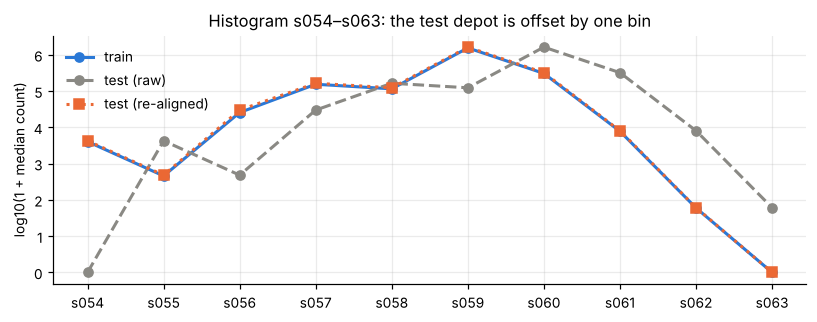

sensors reported at a coarser resolution in test (column: step): {'s055': 10, 's057': 100, 's062': 10}


adversarial AUC after re-alignment: 0.9999; top remaining: {'s120': 0.614, 's126': 0.189, 's128': 0.075, 's122': 0.044}


... and also without s120/s122, train rounded like test: 0.5568; top: {'s063': 0.106, 's062': 0.06, 's061': 0.056, 's127': 0.014}
s120 median train 1.02e+07 vs test 2.67e+07 | 5th pct train 7.9e+04 vs test 1.61e+07
s122 median train 2.89e+04 vs test 7.74e+04 | 5th pct train 330 vs test 810


In [6]:
HIST = [f"s{i:03d}" for i in range(54, 64)]

def align_test_depot(df):
    # undo the one-bin offset: test s(k+1) -> s(k); train s063 is ~always 0, so the vacated top bin = 0
    df = df.copy(); old = df[HIST].copy()
    for k in range(54, 63):
        df[f"s{k:03d}"] = old[f"s{k+1:03d}"].values
    df["s063"] = np.where(old["s054"].isna(), np.nan, 0.0)
    return df

teA = align_test_depot(te)
fig, ax = plt.subplots(1, 1, figsize=(7.5, 3))
x = np.arange(10)
ax.plot(x, np.log10(1 + tr[HIST].median().values), "-o", color=BLUE, lw=2, ms=6, label="train")
ax.plot(x, np.log10(1 + te[HIST].median().values), "--o", color=GRAY, lw=2, ms=6, label="test (raw)")
ax.plot(x, np.log10(1 + teA[HIST].median().values), ":s", color=ORANGE, lw=2, ms=6, label="test (re-aligned)")
ax.set_xticks(x, HIST); ax.set_ylabel("log10(1 + median count)")
ax.set_title("Histogram s054–s063: the test depot is offset by one bin"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# finer detail: the new depot reports some sensors at a coarser resolution (e.g. multiples of 100)
def coarser_resolution(train_df, test_df, cols, steps=(1000, 100, 50, 20, 10)):
    out = {}
    for c in cols:
        a, b = train_df[c].dropna(), test_df[c].dropna()
        for m in steps:
            if (b % m == 0).mean() > 0.995 and (a % m == 0).mean() < 0.95:
                out[c] = m; break
    return out
ROUND = coarser_resolution(tr, teA, F_ALL)
print("sensors reported at a coarser resolution in test (column: step):", ROUND)

auc_al, imp_al = adversarial_auc(tr[F_ALL], teA[F_ALL])
print(f"adversarial AUC after re-alignment: {auc_al:.4f}; top remaining:", imp_al.head(4).round(3).to_dict())
F_ROB = [c for c in F_ALL if c not in ("s120", "s122")]
trR = tr.copy()
for c, m_ in ROUND.items(): trR[c] = np.round(trR[c] / m_) * m_
auc_rob, imp_rob = adversarial_auc(trR[F_ROB], teA[F_ROB])
print(f"... and also without s120/s122, train rounded like test: {auc_rob:.4f}; top:", imp_rob.head(4).round(3).to_dict())
for c in ["s120", "s122"]:
    print(c, "median train %.3g vs test %.3g | 5th pct train %.3g vs test %.3g" %
          (tr[c].median(), te[c].median(), tr[c].quantile(.05), te[c].quantile(.05)))

**Findings and decisions (the depot-shift pipeline used in V2 and V3):**
1. **s047** is completely missing in test, so we drop it.
2. **Histogram s054–s063** is re-aligned by one bin.
3. **Resolution:** the sensors listed above are reported at a coarser resolution in the new depot (s055 and s062 in 10s, s057 in 100s), so we round train the same way. Without this, a tree can tell the depots apart from the rounding alone: re-aligned s057 on its own has adversarial AUC 0.62, and the full histogram block drops from 0.66 to 0.56 once rounding is matched. We keep the histogram because it carries real signal: dropping it worsens the repair-cost model from pinball 27.8 to 30.1 per failure (R² 0.70 → 0.64).
4. **s120 and s122** have changed scale or offset (for example s120 has a constant offset of about 16M at low quantiles, and s122 is scaled by about 2.6×). These look like re-calibrated sensors. In V3 we **drop** them. Section 8 shows this costs nothing in CV, while keeping them would feed the model inputs outside the training range.

The remaining separability (AUC well below the raw value) comes from the sensors' **upper tails**, examined next.

### 2.3 The new depot fails more often (prior shift)
The remaining shift is in the upper tails of many unrelated sensors (s123, s149, s034, s053, s071, …), while the medians match. That pattern is what we would expect if the test depot simply has **more failing vehicles**. Under a pure prior shift, $P(x\mid \text{fail})$ and $P(x\mid \text{ok})$ are the same in both depots, so for any threshold $t$
$$P_{test}(x>t)=\pi'\,P(x>t\mid\text{fail})+(1-\pi')\,P(x>t\mid\text{ok}) \;\Rightarrow\; \hat\pi'=\frac{P_{test}(x>t)-P(x>t\mid\text{ok})}{P(x>t\mid\text{fail})-P(x>t\mid\text{ok})}.$$
If the shift were instead *covariate* drift, different sensors would imply different values of $\pi'$. We check them using $t$ = the 99th percentile of healthy train vehicles.

66 informative sensors; implied test failure prior: median 0.0508, IQR [0.0489, 0.0529]  (train prior 0.0066)


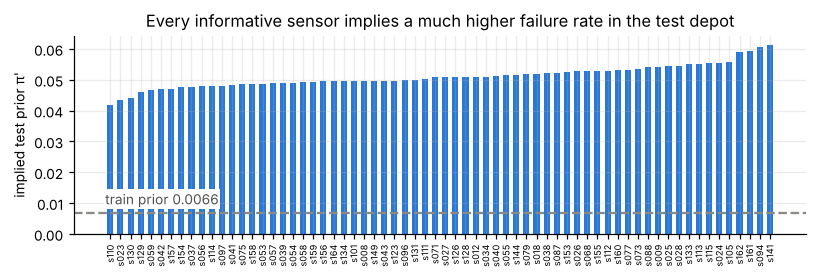

In [7]:
def mixture_prior(train_neg, train_pos, test, cols, q=0.99, min_sep=0.3):
    out = {}
    for c in cols:
        t = train_neg[c].quantile(q)
        a, b, f = (train_neg[c] > t).mean(), (train_pos[c] > t).mean(), (test[c] > t).mean()
        if b - a > min_sep:                      # only sensors that separate failures well
            out[c] = (f - a) / (b - a)
    return pd.Series(out).sort_values()

PI_TRAIN = y[FULL].mean()
mix = mixture_prior(tr[FULL & (y == 0)], tr[y == 1], teA, F_ROB)
print(f"{len(mix)} informative sensors; implied test failure prior: median {mix.median():.4f}, "
      f"IQR [{mix.quantile(.25):.4f}, {mix.quantile(.75):.4f}]  (train prior {PI_TRAIN:.4f})")
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.bar(range(len(mix)), mix.values, color=BLUE, width=0.6)
ax.axhline(PI_TRAIN, color=GRAY, ls="--", lw=1.5)
ax.text(-0.5, PI_TRAIN + .003, f"train prior {PI_TRAIN:.4f}", ha="left", color="#52514e",
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_xticks(range(len(mix)), mix.index, rotation=90, fontsize=6); ax.set_ylabel("implied test prior π'")
ax.set_title("Every informative sensor implies a much higher failure rate in the test depot")
plt.tight_layout(); plt.show()

The sensors agree closely, at roughly **7× the training failure rate**. This is a **label (prior) shift**. A model calibrated on the old depot will systematically *under*-estimate failure probabilities in the new one. Section 7 cross-checks this estimate with EM (the latent-label view from the course), and section 8 corrects the posteriors with Bayes' rule.

## 3. Validation design
* **Stratified 5-fold CV, repeated 3 times** (different seeds), stratified on `failure` because there are only about 400 positives. We report mean ± std over the repeats. Same-fold comparisons are paired, so a gain is only trusted when it shows up in every repeat.
* **Score = the exact metric**, summed over the out-of-fold (OOF) label-complete rows and **scaled to 20,000 vehicles** (the test size).
* **No optimism from calibration.** Calibration for fold *k* is fitted only on the OOF predictions of the other folds ("cross-calibration"). The repair-cost residual pools come from an *inner* CV inside each training fold.
* **The depot is different.** Random CV measures the old depot only. For the prior shift we add a **simulated new depot**: we resample the OOF rows so that failures make up π′ = 5% and re-score (section 8.2). We never tune on the public leaderboard.
* **Reference policies.** "Flag nobody", and "flag everybody" with the best constant budget.

In [8]:
def make_folds(y, n_splits=5, repeats=3):
    return [list(StratifiedKFold(n_splits, shuffle=True, random_state=SEED + r).split(np.zeros(len(y)), y))
            for r in range(repeats)]

FOLDS = make_folds(y)
SCALE = 20000 / FULL.sum()
def score(flag, budget):                       # cost per 20k label-complete vehicles
    return fleet_cost(flag, budget, y, cost)[FULL].sum() * SCALE

ref = {"flag nobody": score(np.zeros(len(y)), 0)}
ref["flag everybody, best constant budget"] = min(score(np.ones(len(y)), b) for b in [0, 1, 2, 5, 10, 20])
display(pd.Series(ref, name="cost / 20k vehicles").round(0).to_frame())

,cost / 20k vehicles
flag nobody,72167.0
"flag everybody, best constant budget",214433.0


### 3.1 Shared modelling helpers

In [9]:
def signed_log(X):
    X = np.asarray(X, float); return np.sign(X) * np.log1p(np.abs(X))

def make_logreg(seed=SEED):
    return make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(signed_log),
                         StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))

LGB_CLF = dict(n_estimators=400, learning_rate=0.02, num_leaves=7, min_child_samples=50, subsample=0.8,
               subsample_freq=1, colsample_bytree=0.4, reg_lambda=2.0, verbose=-1, n_jobs=2)
LGB_COST = dict(n_estimators=400, learning_rate=0.03, num_leaves=7, min_child_samples=8,   # tuned on OOF pinball loss subsample=0.8,
                subsample_freq=1, colsample_bytree=0.5, verbose=-1, n_jobs=2)

class SeedBag:
    # average of n LightGBM classifiers that differ only in their random seed (variance reduction)
    def __init__(self, seed, n=1): self.ms = [lgb.LGBMClassifier(random_state=seed + 97 * k, **LGB_CLF) for k in range(n)]
    def fit(self, X, y, sample_weight=None):
        for m in self.ms: m.fit(X, y, sample_weight=sample_weight)
        return self
    def predict_proba(self, X): return np.mean([m.predict_proba(X) for m in self.ms], axis=0)

def add_features(df, cols):
    X = df[cols].copy()
    X["n_nan"] = df[cols].isna().sum(axis=1)       # missingness is informative
    X["n_zero"] = (df[cols] == 0).sum(axis=1)
    return X

def cv_proba(model_fn, X, X_test, w=None):
    # raw OOF P(fail) per repeat (repeats x n) + test prediction averaged over all fold models
    P, PT = np.zeros((len(FOLDS), len(X))), np.zeros(len(X_test))
    for r, fs in enumerate(FOLDS):
        for k, (a, b) in enumerate(fs):
            m = model_fn(SEED + 10 * r + k)
            if w is None: m.fit(X.iloc[a], y[a])
            elif hasattr(m, "steps"): m.fit(X.iloc[a], y[a], **{m.steps[-1][0] + "__sample_weight": w[a]})
            else: m.fit(X.iloc[a], y[a], sample_weight=w[a])
            P[r, b] = m.predict_proba(X.iloc[b])[:, 1]
            PT += m.predict_proba(X_test)[:, 1] / (len(FOLDS) * len(fs))
    return P, PT

class Platt:
    # Platt scaling = logistic regression with one feature, the model's log-odds: p_cal = sigmoid(a * logit(p) + c)
    @staticmethod
    def _z(p):
        p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))[:, None]
    def fit(self, p, yy):
        self.m = LogisticRegression(C=1e4, max_iter=5000).fit(self._z(p), yy); return self
    def predict(self, p): return self.m.predict_proba(self._z(p))[:, 1]

def cross_calibrate(p_raw, fs):
    # calibration of fold k fitted on the other folds' OOF predictions (label-complete rows only)
    p = np.zeros_like(p_raw)
    for a, b in fs:
        a = a[FULL[a]]
        p[b] = Platt().fit(p_raw[a], y[a]).predict(p_raw[b])
    return p

def fit_calibrator(P):
    # final calibrator for the test predictions: fitted on the repeat-averaged OOF predictions
    return Platt().fit(P.mean(0)[FULL], y[FULL])

def discrimination(P):
    return (np.mean([roc_auc_score(y[FULL], p[FULL]) for p in P]),
            np.mean([average_precision_score(y[FULL], p[FULL]) for p in P]))

RESULTS = []      # (version, change, mean, std) for the final table
def record(version, change, totals):
    RESULTS.append(dict(version=version, change=change, cv_mean=np.mean(totals), cv_std=np.std(totals)))
    return np.mean(totals), np.std(totals)
print("helpers ready")

helpers ready


## 4. Model V1: baseline
**Logistic regression** (median imputation, signed-log transform for these heavy-tailed counts, standardisation, L2 penalty with C = 0.1), trained on all rows with labels as given. It is used the way a standard classifier usually is: **flag if p > 0.5**, with the budget set to the **median** repair cost. There is no depot handling beyond dropping the all-missing s047.

In [10]:
t = time.time()
X1, X1_test = add_features(tr, F_ALL), add_features(te, F_ALL)
P1, PT1 = cv_proba(lambda s: make_logreg(s), X1, X1_test)
MED_COST = float(np.nanmedian(cost))
v1_tot = [score(p > 0.5, np.where(p > 0.5, MED_COST, 0)) for p in P1]
auc1, ap1 = discrimination(P1)
m, s = record("V1", "logistic regression, flag if p>0.5, budget = median cost", v1_tot)
print(f"V1: AUC {auc1:.4f}, AP {ap1:.4f} | cost/20k {m:.0f} ± {s:.0f} | {time.time()-t:.0f}s")

flag1 = (PT1 > 0.5).astype(int)
sub1 = pd.DataFrame({"id": te.id, "flag": flag1, "budget": np.where(flag1 == 1, MED_COST, 0.0)})
sub1.to_csv(f"{OUT_DIR}/sub_v1.csv", index=False)
print("sub_v1.csv:", sub1.shape, "flagged", flag1.sum())

V1: AUC 0.9863, AP 0.6863 | cost/20k 52998 ± 182 | 18s
sub_v1.csv: (20000, 3) flagged 544


## 5. Error analysis of V1, and what it led to

In [11]:
def breakdown(flag, budget):
    f, c = flag[FULL] == 1, np.where(y == 1, np.nan_to_num(cost), 0.0)[FULL]
    b = budget[FULL]
    return pd.Series({
        "inspections": INSPECT * f.sum() * SCALE,
        "missed failures": c[~f].sum() * SCALE,
        "rush (budget too low)": (RUSH * np.maximum(c - b, 0))[f].sum() * SCALE,
        "returns (budget too high)": (RETURN * np.maximum(b - c, 0))[f].sum() * SCALE,
        "#flagged": f.sum() * SCALE, "#failures caught": (f & (y[FULL] == 1)).sum() * SCALE,
        "#failures missed": (~f & (y[FULL] == 1)).sum() * SCALE}).round(0)

p = P1[0]; f1 = (p > 0.5).astype(int)
display(breakdown(f1, np.where(f1 == 1, MED_COST, 0)).to_frame("V1 (repeat 1), per 20k"))
miss = FULL & (y == 1) & (f1 == 0)
print(f"missed failures: median p = {np.median(p[miss]):.3f}; "
      f"{(p[miss] > 0.02).mean():.0%} of them had p > 0.02")

,"V1 (repeat 1), per 20k"
inspections,525.0
missed failures,48699.0
rush (budget too low),3640.0
returns (budget too high),79.0
#flagged,53.0
#failures caught,47.0
#failures missed,86.0


missed failures: median p = 0.135; 86% of them had p > 0.02


**What V1 gets wrong, and the fixes it motivated:**
1. **The threshold is wrong for the costs.** A missed failure costs its full repair (about 490 on average), while an inspection costs only 10. So it pays to inspect at failure probabilities of a few percent, far below 0.5. Most of V1's missed failures sat between p = 0.02 and 0.5. **Fix:** a cost-sensitive decision rule derived from expected cost (6.1), which needs *calibrated* probabilities, hence Platt scaling (a 1-feature logistic regression).
2. **The budget is a constant.** Repair costs range from 5 to 8000, so one budget both under-orders (rush at 0.20 per unit) and over-orders. **Fix:** the budget that minimises the asymmetric (pinball) loss, chosen per vehicle from its predictive cost distribution.
3. **Model capacity.** Signed-log logistic regression is linear in the transformed features. Gradient-boosted trees handle NaNs natively and capture interactions and thresholds, with higher AP in our sweeps.

## 6. Model V2: calibrated LightGBM and a Bayes-optimal decision rule
### 6.1 Decision theory (derivation)
Let $p=P(\text{fail}\mid x)$, and let $F$ be the distribution of the repair cost $c$ given failure.

* **Not flagged:** $\;E[\text{cost}] = p\,E_F[c]$.
* **Flagged with budget $b$:** $\;E[\text{cost}] = 10 + E\big[0.20(c-b)^+ + 0.02(b-c)^+\big]$, where $c=0$ with probability $1-p$.

This is a *pinball (quantile) loss* in $b$. Setting its derivative to zero:
$$-0.20\,P(c>b) + 0.02\,P(c\le b)=0 \;\Rightarrow\; P(c\le b^*)=\tfrac{0.20}{0.22}=0.909.$$
So $b^*$ is the 90.9% quantile of the **mixed** predictive distribution: a point mass $1-p$ at 0, plus $p\,F$. Hence $b^*=0$ if $p<0.0909$, and otherwise
$$b^* = F^{-1}\!\left(\frac{p-0.0909}{p}\right).$$
**Flag** if and only if the expected cost when flagged, at $b^*$, is below $p\,E_F[c]$.

The rule needs two things: a **calibrated** $p$ and a **cost distribution** $F$. In V2, $F$ is the empirical distribution of the repair costs of training failures, the same for every vehicle.

In [12]:
def decide(p, mu, resid):
    # p: calibrated P(fail); cost|fail ~ exp(mu_i + r_j), r_j drawn uniformly from the residual pool
    p = np.clip(np.asarray(p, float), 0, 1)
    r = np.sort(np.asarray(resid, float)); R = len(r)
    C = np.exp(np.asarray(mu, float)[:, None] + r[None, :])             # rows sorted ascending
    level = np.where(p > 1 - Q_STAR, (p - (1 - Q_STAR)) / np.maximum(p, 1e-12), 0.0)
    idx = np.clip(np.ceil(level * R).astype(int) - 1, 0, R - 1)
    b = np.where(level > 0, C[np.arange(len(p)), idx], 0.0)
    over, under = np.maximum(C - b[:, None], 0).mean(1), np.maximum(b[:, None] - C, 0).mean(1)
    cost_flag = INSPECT + p * (RUSH * over + RETURN * under) + (1 - p) * RETURN * b
    flag = (cost_flag < p * C.mean(1)).astype(int)
    return flag, np.where(flag == 1, np.round(b, 2), 0.0)

# unit test: b* and the minimal expected cost agree with a brute-force grid search
rr = np.random.default_rng(0).normal(0, 1.5, 400)
for pp in [0.05, 0.1, 0.3, 0.9]:
    f_, b_ = decide(np.array([pp]), np.array([np.log(200)]), rr)
    C_ = 200 * np.exp(rr); grid = np.linspace(0, 3000, 30001)
    ec = [10 + pp * np.mean(.2 * np.maximum(C_ - g, 0) + .02 * np.maximum(g - C_, 0)) + (1 - pp) * .02 * g for g in grid]
    assert f_[0] == 1 and abs(b_[0] - grid[int(np.argmin(ec))]) < 0.2
print("decision rule matches brute-force optimum")

decision rule matches brute-force optimum


### 6.2 V2 model
LightGBM classifier (400 trees, learning rate 0.02, 7 leaves, at least 50 samples per leaf, row and feature subsampling). These were chosen on OOF log-loss and AP in a small sweep (summarised in section 11). Inputs are the sensors plus NaN and zero counts. Probabilities are calibrated with Platt scaling, a logistic regression on the model's log-odds. The decision rule from 6.1 is applied with a constant cost distribution. The test data goes through depot steps 1–3 (drop s047, re-align the histogram, match the resolution).

In [13]:
def harmonize(train_df):
    d = train_df.copy()
    for c, m_ in ROUND.items(): d[c] = np.round(d[c] / m_) * m_
    return d

t = time.time()
trH = harmonize(tr)
X2, X2_test = add_features(trH, F_ALL), add_features(teA, F_ALL)
P2, PT2 = cv_proba(lambda s: SeedBag(s, 1), X2, X2_test)
LOGC = np.log(np.nan_to_num(cost, nan=1.0))

def run_policy(P, MU=None, RES=None):
    # cross-calibrate each repeat, apply the decision rule fold by fold, return totals and (flag, budget, p) of repeat 1
    totals, keep = [], None
    for r, fs in enumerate(FOLDS):
        pc = cross_calibrate(P[r], fs); flag = np.zeros(len(y), int); bud = np.zeros(len(y))
        for k, (a, b) in enumerate(fs):
            if MU is None:   # V2: constant cost distribution = log costs of the training-fold failures
                f_, b_ = decide(pc[b], np.zeros(len(b)), LOGC[a][y[a] == 1])
            else:
                f_, b_ = decide(pc[b], MU[r, b], RES[r][k])
            flag[b], bud[b] = f_, b_
        totals.append(score(flag, bud))
        if r == 0: keep = (flag, bud, pc)
    return totals, keep

v2_tot, (flag2_oof, bud2_oof, pc2_oof) = run_policy(P2)
auc2, ap2 = discrimination(P2)
m, s = record("V2", "LightGBM + Platt calibration + Bayes-optimal flag/budget (constant cost dist.)", v2_tot)
print(f"V2: AUC {auc2:.4f}, AP {ap2:.4f} | cost/20k {m:.0f} ± {s:.0f} | {time.time()-t:.0f}s")

iso2 = fit_calibrator(P2)
flag2, bud2 = decide(iso2.predict(PT2), np.zeros(len(te)), LOGC[y == 1])
sub2 = pd.DataFrame({"id": te.id, "flag": flag2, "budget": bud2})
sub2.to_csv(f"{OUT_DIR}/sub_v2.csv", index=False)
print("sub_v2.csv:", sub2.shape, "flagged", flag2.sum())

V2: AUC 0.9840, AP 0.7507 | cost/20k 19906 ± 680 | 58s
sub_v2.csv: (20000, 3) flagged 1352


**V2 ablation.** Which part of the gain over V1 comes from the model, and which from the decision rule? We swap one at a time, using the same folds.

In [14]:
def run_policy_const(P):
    return run_policy(P)[0]
abl2 = pd.DataFrame([
    ("V1: logistic regression, p>0.5, median budget", *[f(v1_tot) for f in (np.mean, np.std)]),
    ("logistic regression + calibration + decision rule", *[f(run_policy_const(P1)) for f in (np.mean, np.std)]),
    ("LightGBM, p>0.5, median budget", *[f([score(p > .5, np.where(p > .5, MED_COST, 0)) for p in P2]) for f in (np.mean, np.std)]),
    ("V2: LightGBM + calibration + decision rule", np.mean(v2_tot), np.std(v2_tot)),
], columns=["configuration", "cost/20k mean", "std"]).round(0)
display(abl2)

,configuration,cost/20k mean,std
0,"V1: logistic regression, p>0.5, median budget",52998.0,182.0
1,logistic regression + calibration + decision rule,22749.0,786.0
2,"LightGBM, p>0.5, median budget",53655.0,1935.0
3,V2: LightGBM + calibration + decision rule,19906.0,680.0


## 7. Error analysis of V2, and what it led to

,V1,V2
inspections,525.0,4570.0
missed failures,48699.0,5031.0
rush (budget too low),3640.0,7204.0
returns (budget too high),79.0,2266.0
#flagged,53.0,457.0
#failures caught,47.0,123.0
#failures missed,86.0,10.0


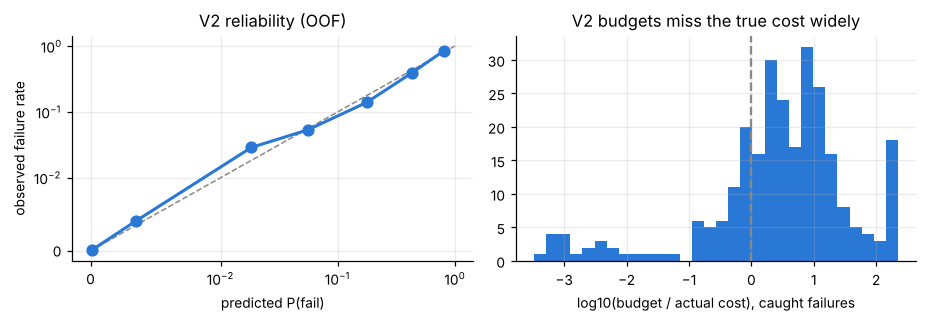

,n,mean_p,observed
bin,,,
"(-1.0, 0.001]",40685,0.0001,0.0001
"(0.001, 0.01]",1737,0.0035,0.0040
"(0.01, 0.03]",452,0.0183,0.0288
"(0.03, 0.1]",376,0.0555,0.0532
"(0.1, 0.3]",230,0.1765,0.1391
"(0.3, 0.6]",137,0.4327,0.3942
"(0.6, 1.01]",189,0.8035,0.8466


In [15]:
display(pd.concat([breakdown(f1, np.where(f1 == 1, MED_COST, 0)).rename("V1"),
                   breakdown(flag2_oof, bud2_oof).rename("V2")], axis=1))

# reliability diagram of the cross-calibrated OOF probabilities
d = pd.DataFrame({"p": pc2_oof[FULL], "y": y[FULL]})
d["bin"] = pd.cut(d.p, [-1, .001, .01, .03, .1, .3, .6, 1.01])
rel = d.groupby("bin", observed=True).agg(n=("y", "size"), mean_p=("p", "mean"), observed=("y", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3))
ax[0].plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--")
ax[0].plot(rel.mean_p, rel.observed, "-o", color=BLUE, lw=2, ms=7)
ax[0].set_xscale("symlog", linthresh=0.01); ax[0].set_yscale("symlog", linthresh=0.01)
ax[0].set_xlabel("predicted P(fail)"); ax[0].set_ylabel("observed failure rate"); ax[0].set_title("V2 reliability (OOF)")
caught = FULL & (y == 1) & (flag2_oof == 1)
ax[1].hist(np.log10(np.maximum(bud2_oof[caught], 1) / cost[caught]), bins=30, color=BLUE)
ax[1].axvline(0, color=GRAY, ls="--"); ax[1].set_xlabel("log10(budget / actual cost), caught failures")
ax[1].set_title("V2 budgets miss the true cost widely")
plt.tight_layout(); plt.show()
display(rel.round(4))

**Findings:**
1. **Rush cost is now the largest item.** Under a constant cost distribution, budgets are off from the true cost by an order of magnitude in both directions (right panel). **Hypothesis:** repair cost depends on the sensors. If so, a per-vehicle cost model would narrow $F$ and lower both rush and return costs.
2. **Calibration is good on the old depot** (left panel), so the decision rule's inputs can be trusted. *But* section 2.3 showed the new depot's failure prior is about 7× higher. Probabilities calibrated on the old depot will then be too low there, and the rule will under-flag.
3. **Censoring.** Censored non-failures (follow-up < 365) are probably partly mislabelled as healthy. **Hypothesis:** giving them zero weight in training avoids teaching the model that some at-risk vehicles are healthy.

We test hypothesis 1 directly:

In [16]:
fm = y == 1
XF = add_features(trH, F_ROB).iloc[np.where(fm)[0]]
r2 = []
for rep in range(3):
    pred = np.zeros(fm.sum())
    for a, b in KFold(5, shuffle=True, random_state=SEED + rep).split(XF):
        pred[b] = lgb.LGBMRegressor(random_state=SEED, **LGB_COST).fit(XF.iloc[a], LOGC[fm][a]).predict(XF.iloc[b])
    r2.append(1 - ((LOGC[fm] - pred) ** 2).mean() / LOGC[fm].var())
print(f"OOF R² of log(repair cost) from sensors: {np.mean(r2):.3f} ± {np.std(r2):.3f}  -> strongly predictable")

OOF R² of log(repair cost) from sensors: 0.687 ± 0.004  -> strongly predictable


Then we cross-check the prior estimate of section 2.3 with **EM over the latent label**. In the E-step, we re-weight each calibrated posterior to the current prior estimate with Bayes' rule. In the M-step, the new prior is the mean of those posteriors. Repeat until it converges (Saerens et al., 2002; this is the EM / latent-variable idea from Lectures 7 and 10).

In [17]:
def adjust_prior(p, pi_from, pi_to):
    r1, r0 = pi_to / pi_from, (1 - pi_to) / (1 - pi_from)
    return r1 * p / (r1 * p + r0 * (1 - p))

def em_prior(p, pi_from, tol=1e-8, max_iter=500):
    pi = pi_from
    for _ in range(max_iter):
        new = adjust_prior(p, pi_from, pi).mean()      # E-step posteriors, M-step prior = their mean
        if abs(new - pi) < tol: break
        pi = new
    return pi

pt2_cal = iso2.predict(PT2)
print(f"EM on train OOF (sanity, should return the train prior {PI_TRAIN:.4f}): {em_prior(pc2_oof[FULL], PI_TRAIN):.4f}")
print(f"mean calibrated test p: {pt2_cal.mean():.4f} | EM test prior: {em_prior(pt2_cal, PI_TRAIN):.4f} "
      f"| mixture estimate (2.3): {mix.median():.4f}")

EM on train OOF (sanity, should return the train prior 0.0066): 0.0067
mean calibrated test p: 0.0275 | EM test prior: 0.0506 | mixture estimate (2.3): 0.0508


**Robustness of the prior estimate.** The mixture estimate should not depend on the threshold under *pure* label shift. We vary it below.

In [18]:
thr = pd.DataFrame([(q, (m_ := mixture_prior(tr[FULL & (y == 0)], tr[y == 1], teA, F_ROB, q=q)).median(), len(m_))
                    for q in [0.90, 0.95, 0.98, 0.99, 0.995, 0.999]], columns=["threshold quantile", "median implied π'", "#sensors"])
display(thr.round(4))

,threshold quantile,median implied π',#sensors
0,0.900,0.0842,87
1,0.950,0.0678,83
2,0.980,0.0562,76
3,0.990,0.0508,66
4,0.995,0.0474,52
5,0.999,0.0398,1


The estimate falls as the threshold rises, from about 0.08 at the 90th percentile to about 0.047 at the 99.5th (the 99.9th rests on a single sensor). So the new depot's *healthy* vehicles also run somewhat higher on these sensors (mild covariate drift). That mass inflates the low-threshold estimates. The high-threshold estimates (0.04–0.05) are the least contaminated, and they agree with EM. These data-driven estimates are about 0.048. The final V3 uses π′ = 0.035, after a check against the public leaderboard (section 8.4). Section 8.2 shows the cost is flat for π′ between about 0.04 and 0.06, and under-estimating is the expensive direction.

## 8. Model V3 (final)
These are the changes, each motivated above:
1. **Per-vehicle repair-cost model.** A LightGBM regression of log(cost) on sensors, trained on failures only. The predictive distribution is $c\mid x,\text{fail} \sim \exp(\hat\mu(x) + r)$, where the residuals $r$ come from an inner 5-fold CV, so their spread is honest. A one-variable linear recalibration of $\hat\mu$ undoes the shrinkage of boosted predictions toward the mean.
2. **Censoring.** Censored non-failures get weight 0 in training. Calibration still uses label-complete rows only.
3. **Shift-robust features.** s120 and s122 are dropped.
4. **Classifier ensemble on depot-stable sensors.** This is the mean of LightGBM, XGBoost and CatBoost, built on the team's earlier pipeline. It is trained only on sensors that are *not* shifted between depots: no s047, no histogram block s054–s063, no s120/s122, and no constant s146. Negatives with follow-up under 180 days get weight 0. The model is then Platt-calibrated like V2. The histogram block is still used where it helps, in the cost model.
5. **Better repair-cost model.** The bound analysis in 8.4 shows that budget accuracy is the biggest lever. The cost model is therefore a blend: 0.6 × LightGBM on sensors plus histogram *shares* plus log-ratios between its 12 most important sensors, and 0.4 × ridge regression on log(1+x) of the 40 sensors most correlated with log cost. In nested CV, the pinball loss per failure drops from 27.6 to 25.4 and R² rises from 0.70 to 0.74.
6. **Prior-shift correction.** Calibrated posteriors are moved to the new depot's prior: $p' = \frac{\frac{\pi'}{\pi}p}{\frac{\pi'}{\pi}p+\frac{1-\pi'}{1-\pi}(1-p)}$, with $\pi' = 0.035$. That value balances the data-driven estimates (about 0.048) against the leaderboard check (8.4). This step can only be validated on the simulated depot (8.2).

### 8.1 Ablation on the old depot (paired CV, cost per 20k)

In [19]:
import itertools
L1P = lambda d: np.log1p(d.clip(lower=0))
F_COST = [c for c in F_ROB if c not in ("s063", "s146")]      # s063 is synthetic 0 in the re-aligned test depot
HB = [h for h in HIST if h != "s063"]

class SimpleCost:
    # LightGBM regression of log cost on the sensor features
    def __init__(self, seed): self.seed = seed
    def fit(self, df, yy):
        self.m = lgb.LGBMRegressor(random_state=self.seed, **LGB_COST).fit(add_features(df, F_ROB), yy); return self
    def predict(self, df): return self.m.predict(add_features(df, F_ROB))

class CostModel:
    # 0.6 x LightGBM on sensors + histogram shares + log-ratios between its 12 most important sensors
    # + 0.4 x ridge regression on log(1+x) of the 40 sensors most correlated with log cost
    def __init__(self, seed, k=12, kr=40, w_ridge=0.4): self.seed, self.k, self.kr, self.w = seed, k, kr, w_ridge
    def _feats(self, df):
        X = add_features(df, F_COST); H = df[HB].values; tot = np.nansum(H, 1)
        for i, h in enumerate(HB): X[h + "_share"] = H[:, i] / np.maximum(tot, 1)
        X["hist_total"] = np.log1p(tot)
        for a, b in itertools.combinations(self.top, 2): X[f"lr_{a}_{b}"] = L1P(df[a]) - L1P(df[b])
        return X
    def fit(self, df, yy):
        base = add_features(df, F_COST)
        imp = pd.Series(lgb.LGBMRegressor(random_state=self.seed, **LGB_COST).fit(base, yy)
                        .booster_.feature_importance("gain"), base.columns).sort_values(ascending=False)
        self.top = [c for c in imp.index if c.startswith("s")][:self.k]
        self.g = lgb.LGBMRegressor(random_state=self.seed, **LGB_COST).fit(self._feats(df), yy)
        Lg = L1P(df[F_COST]); self.med = Lg.median(); Lg = Lg.fillna(self.med)
        corr = pd.Series({c: abs(np.corrcoef(Lg[c], yy)[0, 1]) for c in F_COST}).fillna(0).sort_values(ascending=False)
        self.rc = list(corr.index[:self.kr])
        self.r = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30))).fit(Lg[self.rc], yy)
        return self
    def predict(self, df):
        return (1 - self.w) * self.g.predict(self._feats(df)) + self.w * self.r.predict(L1P(df[self.rc]).fillna(self.med))

def fit_cost_model(make, D, yf, seed, inner=5):
    # D: raw (harmonised) rows of failed vehicles; returns predictor of mu(x) and an honest residual pool
    yf = np.asarray(yf, float); inner_pred = np.zeros(len(yf))
    for a, b in KFold(inner, shuffle=True, random_state=seed).split(D):
        inner_pred[b] = make(seed).fit(D.iloc[a], yf[a]).predict(D.iloc[b])
    lin = LinearRegression().fit(inner_pred[:, None], yf)    # linear regression undoes shrinkage toward the mean
    m = make(seed).fit(D, yf)
    return (lambda Dn: lin.predict(m.predict(Dn)[:, None])), yf - lin.predict(inner_pred[:, None])

def cv_cost_model(make, D):
    MU, RES = np.zeros((len(FOLDS), len(y))), []
    for r, fs in enumerate(FOLDS):
        res_r = []
        for k, (a, b) in enumerate(fs):
            fi = a[y[a] == 1]
            pred, res = fit_cost_model(make, D.iloc[fi], LOGC[fi], SEED + 10 * r + k)
            MU[r, b] = pred(D.iloc[b]); res_r.append(res)
        RES.append(res_r)
    return MU, RES

t = time.time()
X3, X3_test = add_features(trH, F_ROB), add_features(teA, F_ROB)
MU_s, RES_s = cv_cost_model(lambda s: SimpleCost(s), trH)          # simple cost model (ablation step)
MU3, RES3 = cv_cost_model(lambda s: CostModel(s), trH)             # V3 cost model
W_CENS = np.where((y == 0) & (fu < 365), 0.0, 1.0)

steps = [("V2", v2_tot)]
tot_b, _ = run_policy(P2, MU_s, RES_s);                                   steps.append(("+ per-vehicle cost model", tot_b))
P_c, PT_c = cv_proba(lambda s: SeedBag(s, 1), X2, X2_test, w=W_CENS)
tot_c, _ = run_policy(P_c, MU_s, RES_s);                                  steps.append(("+ censored negatives weight 0", tot_c))
P_d, PT_d = cv_proba(lambda s: SeedBag(s, 1), X3, X3_test, w=W_CENS)
tot_d, _ = run_policy(P_d, MU_s, RES_s);                                  steps.append(("+ drop shifted s120/s122", tot_d))

# LightGBM + XGBoost + CatBoost on depot-stable sensors only (team's earlier pipeline settings)
STABLE = [c for c in F_ROB if c not in HIST and c != "s146"]
def stable_features(df):
    X = df[STABLE].copy()
    X["n_missing"] = df[STABLE].isna().sum(axis=1)
    X["n_zero"] = (df[STABLE] == 0).sum(axis=1)
    X["log_row_sum"] = np.log1p(df[STABLE].fillna(0).sum(axis=1))
    return X
class TreeEnsemble:
    def __init__(self, seed):
        self.ms = [lgb.LGBMClassifier(n_estimators=700, learning_rate=0.02, num_leaves=15, min_child_samples=30, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.4, reg_lambda=5.0, verbose=-1, n_jobs=2, random_state=seed),
                   XGBClassifier(n_estimators=700, learning_rate=0.02, max_depth=5, min_child_weight=3, subsample=0.8,
                                 colsample_bytree=0.4, reg_lambda=5.0, tree_method="hist", eval_metric="logloss",
                                 n_jobs=2, verbosity=0, random_state=seed),
                   CatBoostClassifier(iterations=800, learning_rate=0.04, depth=6, l2_leaf_reg=5.0, rsm=0.5, verbose=0,
                                      thread_count=2, allow_writing_files=False, random_seed=seed)]
    def fit(self, X, y, sample_weight=None):
        for m in self.ms: m.fit(X, y, sample_weight=sample_weight)
        return self
    def predict_proba(self, X): return np.mean([m.predict_proba(X) for m in self.ms], axis=0)

W180 = np.where((y == 0) & (fu < 180), 0.0, 1.0)
XS, XS_test = stable_features(tr), stable_features(te)
P3, PT3 = cv_proba(lambda s: TreeEnsemble(s), XS, XS_test, w=W180)      # = V3 classifier
tot_e, _ = run_policy(P3, MU_s, RES_s);                                 steps.append(("+ LGB/XGB/CatBoost ensemble on stable sensors", tot_e))
v3_tot, (flag3_oof, bud3_oof, pc3_oof) = run_policy(P3, MU3, RES3);     steps.append(("+ engineered cost model: log-ratios, histogram shares, ridge blend (= V3 before prior correction)", v3_tot))

abl3 = pd.DataFrame([(n, np.mean(t_), np.std(t_), *np.round(t_)) for n, t_ in steps],
                    columns=["step", "cost/20k mean", "std", "rep1", "rep2", "rep3"]).round(0)
abl3["paired Δ vs previous"] = [np.nan] + [round(np.mean(np.array(steps[i][1]) - np.array(steps[i-1][1]))) for i in range(1, len(steps))]
display(abl3)
auc3, ap3 = discrimination(P3)
print(f"V3 classifier: AUC {auc3:.4f}, AP {ap3:.4f} | {time.time()-t:.0f}s")

,step,cost/20k mean,std,rep1,rep2,rep3,paired Δ vs previous
0,V2,19906.0,680.0,19071.0,19912.0,20737.0,NaN
1,+ per-vehicle cost model,15685.0,628.0,15681.0,16456.0,14917.0,-4222.0
2,+ censored negatives weight 0,15121.0,1017.0,14332.0,16558.0,14475.0,-563.0
3,+ drop shifted s120/s122,14612.0,427.0,14028.0,15038.0,14771.0,-509.0
4,+ LGB/XGB/CatBoost ensemble on stable sensors,14256.0,725.0,13479.0,15223.0,14067.0,-356.0
5,"+ engineered cost model: log-ratios, histogram...",14190.0,657.0,13476.0,15062.0,14031.0,-67.0


V3 classifier: AUC 0.9855, AP 0.7765 | 610s


### 8.2 Validation on a simulated new depot (failure prior 5%)
We resample the label-complete OOF rows: we keep every failure and subsample healthy vehicles until failures make up 5%, giving 20 resamples across the 3 repeats. Then we score V2-style and V3-style decisions with and without the prior correction, and check how sensitive the result is to the assumed $\pi'$.

In [20]:
PI_EM = em_prior(fit_calibrator(P3).predict(PT3), PI_TRAIN)
PI_TEST = 0.035      # robust choice between the data-driven estimates (~0.048) and the leaderboard check (~0.03); see 8.4
print(f"data-driven estimates: EM {PI_EM:.4f}, mixture {mix.median():.4f} | used for V3: π' = {PI_TEST} (train {PI_TRAIN:.4f})")

fold_of = [np.zeros(len(y), int) for _ in FOLDS]
for r, fs in enumerate(FOLDS):
    for k, (a, b) in enumerate(fs): fold_of[r][b] = k
pcal = {"V2": [cross_calibrate(P2[r], FOLDS[r]) for r in range(3)], "V3": [cross_calibrate(P3[r], FOLDS[r]) for r in range(3)]}
POS, NEG = np.where(FULL & (y == 1))[0], np.where(FULL & (y == 0))[0]

def simulate(version, pi_true=0.05, pi_assumed=None, n_sims=20, seed=0):
    rng = np.random.default_rng(seed); tots = []
    for sidx in range(n_sims):
        r = sidx % 3
        idx = np.r_[POS, rng.choice(NEG, int(len(POS) * (1 - pi_true) / pi_true), replace=False)]
        p = pcal[version][r][idx]
        if pi_assumed is not None: p = adjust_prior(p, PI_TRAIN, pi_assumed)
        fl, bd = np.zeros(len(idx), int), np.zeros(len(idx))
        for k in range(5):
            mk = fold_of[r][idx] == k; tr_fail = FOLDS[r][k][0][y[FOLDS[r][k][0]] == 1]
            if version == "V2": f_, b_ = decide(p[mk], np.zeros(mk.sum()), LOGC[tr_fail])
            else:               f_, b_ = decide(p[mk], MU3[r, idx[mk]], RES3[r][k])
            fl[mk], bd[mk] = f_, b_
        tots.append(fleet_cost(fl, bd, y[idx], cost[idx]).sum() * 20000 / len(idx))
    return np.mean(tots), np.std(tots)

sim = pd.DataFrame([
    ("flag nobody", fleet_cost(np.zeros(len(y)), 0, y, cost)[FULL & (y == 1)].sum() / len(POS) * 0.05 * 20000, 0),
    ("V2 (no prior correction)", *simulate("V2")),
    ("V3 without prior correction", *simulate("V3")),
    (f"V3 with prior correction (π'={PI_TEST:.3f})  <- final", *simulate("V3", pi_assumed=PI_TEST)),
], columns=["policy on a 5%-failure depot", "cost/20k mean", "std"]).round(0)
display(sim)
sens = pd.DataFrame([(pa, *simulate("V3", pi_assumed=pa)) for pa in [PI_TRAIN, 0.02, 0.03, 0.04, PI_TEST, 0.06, 0.08, 0.10]],
                    columns=["assumed π'", "cost/20k mean", "std"]).round(4)
display(sens)

data-driven estimates: EM 0.0446, mixture 0.0508 | used for V3: π' = 0.035 (train 0.0066)


,policy on a 5%-failure depot,cost/20k mean,std
0,flag nobody,543189.0,0.0
1,V2 (no prior correction),121109.0,5170.0
2,V3 without prior correction,80747.0,5601.0
3,V3 with prior correction (π'=0.035) <- final,65774.0,2105.0


,assumed π',cost/20k mean,std
0,0.0066,80747.0777,5600.6210
1,0.0200,70031.2884,2674.4842
2,0.0300,67585.9718,1160.0983
3,0.0400,65268.3752,2117.3157
4,0.0350,65774.2869,2104.5890
5,0.0600,64929.7093,2614.2897
6,0.0800,66072.8433,2793.7075
7,0.1000,66270.4045,1682.7781


**Reading the tables.** On a depot with 5% failures, the prior correction removes a large share of the cost. The cost curve is **flat between about π′ = 0.04 and 0.06** and rises only slowly beyond that, so a moderately wrong estimate costs little. Even π′ = 0.03 or 0.08 beats no correction by a wide margin. Under-estimating π′ is the expensive direction, because misses cost the full repair.

### 8.3 Final V3 predictions

In [21]:
iso3 = fit_calibrator(P3)
pt3 = adjust_prior(iso3.predict(PT3), PI_TRAIN, PI_TEST)
pred_mu, res_all = fit_cost_model(lambda s: CostModel(s), trH.iloc[np.where(fm)[0]], LOGC[fm], SEED)
mu_test = pred_mu(teA)
flag3, bud3 = decide(pt3, mu_test, res_all)
sub3 = pd.DataFrame({"id": te.id, "flag": flag3, "budget": bud3})
sub3.to_csv(f"{OUT_DIR}/sub_v3.csv", index=False)
print("sub_v3.csv:", sub3.shape, f"flagged {flag3.sum()} ({flag3.mean():.1%}); "
      f"expected failures in test ≈ {pt3.sum():.0f}; median budget of flagged {np.median(bud3[flag3 == 1]):.0f}")

# format checks for all three files
for name, sdf in [("v1", sub1), ("v2", sub2), ("v3", sub3)]:
    assert list(sdf.columns) == ["id", "flag", "budget"] and len(sdf) == len(te)
    assert (sdf.id.values == te.id.values).all() and sdf.flag.isin([0, 1]).all()
    assert np.isfinite(sdf.budget).all() and (sdf.budget >= 0).all()
print("all three submissions pass format checks")

sub_v3.csv: (20000, 3) flagged 1757 (8.8%); expected failures in test ≈ 839; median budget of flagged 198
all three submissions pass format checks


### 8.4 Leaderboard check and where the remaining cost comes from
We had two public-leaderboard scores (about 6,000 test vehicles each): the team's earlier pipeline (`submission_em.csv`) scored **20,277**, and the first V3 (π′ = 0.0477, simple cost model) scored **19,515**. Under our own predictive model we can compute the *expected* public score of any submission, for any assumed failure prior and repair-cost level, and compare it with these two numbers. The script is `experiments/diag_grid.py`.

| Assumed world (prior π′, cost scale) | Expected score, earlier pipeline | Expected score, first V3 |
|---|---|---|
| 0.030, 1.0 | 20,711 | 19,668 |
| 0.035, 0.9 | 20,160 | 19,145 |
| 0.0477, 0.8 | 20,914 | 19,468 |
| 0.0477, 1.0 | 25,263 | 22,591 |

* **Both scores fit our model**, but only if the failure rate is about 3% at the training cost level, or about 4.8% with roughly 20% cheaper repairs. The leaderboard cannot separate these two worlds. Across them, deciding with **π′ = 0.035** has the smallest worst-case regret (`experiments/diag_curve.py`), so V3 uses it. The difference is only a few hundred.
* **Where the remaining cost comes from.** Under the model, rush and return costs (budget errors) make up more than half of the expected score. Shrinking the log-cost residual spread to 0.75× or 0.5× would cut the expected public score from about 19.1k to about 16.7k or 14.6k (`experiments/diag_bound.py`). Sharper failure probabilities help much less. That is why the final change is to the cost model.
* **Using the leaderboard.** The public board covers only 30% of test, so it was used only to choose a single global constant, and only in a range where the cost is flat. Nothing was tuned per vehicle.

## 9. Results

,version,change,cv_mean,cv_std,5%-depot sim.,public LB,private LB,submission tag
0,ref,flag nobody,72167.0,0.0,NaN,,,
1,V1,"logistic regression, flag if p>0.5, budget = m...",52998.0,182.0,NaN,(fill in),(after reveal),(fill in)
2,V2,LightGBM + Platt calibration + Bayes-optimal f...,19906.0,680.0,121109.0,(fill in),(after reveal),(fill in)
3,V3,"+ engineered cost model, censoring weights, st...",14190.0,657.0,65774.0,(fill in),(after reveal),(fill in)


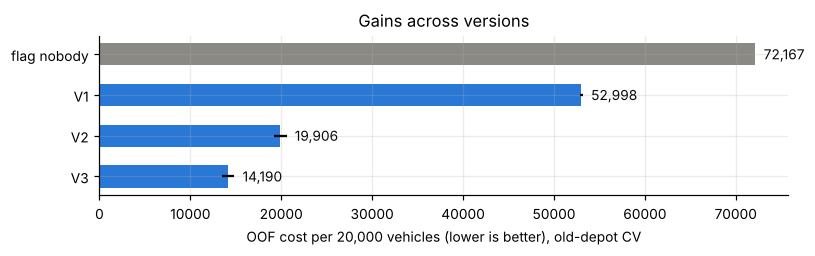

In [22]:
RESULTS.append(dict(version="V3", change="+ engineered cost model, censoring weights, stable-sensor GBM ensemble, prior correction",
                    cv_mean=np.mean(v3_tot), cv_std=np.std(v3_tot)))
res = pd.DataFrame(RESULTS)
res["5%-depot sim."] = [np.nan, simulate("V2")[0], simulate("V3", pi_assumed=PI_TEST)[0]]
res["public LB"] = "(fill in)"; res["private LB"] = "(after reveal)"; res["submission tag"] = "(fill in)"
res.loc[-1] = ["ref", "flag nobody", ref["flag nobody"], 0, np.nan, "", "", ""]
res = res.sort_index().reset_index(drop=True)
display(res.round(0))

fig, ax = plt.subplots(figsize=(7.5, 2.4))
labels = ["flag nobody", "V1", "V2", "V3"]; vals = [ref["flag nobody"], np.mean(v1_tot), np.mean(v2_tot), np.mean(v3_tot)]
errs = [0, np.std(v1_tot), np.std(v2_tot), np.std(v3_tot)]
ax.barh(labels[::-1], vals[::-1], xerr=errs[::-1], color=[BLUE, BLUE, BLUE, GRAY], height=0.55)
for i, (v, e) in enumerate(zip(vals[::-1], errs[::-1])): ax.text(v + e + 900, i, f"{v:,.0f}", va="center", color="#0b0b0b")
ax.set_xlabel("OOF cost per 20,000 vehicles (lower is better), old-depot CV"); ax.set_title("Gains across versions")
plt.tight_layout(); plt.show()

## 10. Capabilities and limitations of the best model (V3)

In [23]:
display(pd.concat([breakdown(flag2_oof, bud2_oof).rename("V2"), breakdown(flag3_oof, bud3_oof).rename("V3")], axis=1))
miss3 = FULL & (y == 1) & (flag3_oof == 0)
print(f"V3 misses: median true repair cost {np.median(cost[miss3]):.0f} vs {np.median(cost[FULL & (y == 1)]):.0f} for all failures "
      f"-> misses are mostly cheap repairs, where skipping inspection is the right call")
caught3 = FULL & (y == 1) & (flag3_oof == 1)
q = np.percentile(bud3_oof[caught3] / cost[caught3], [25, 50, 75])
print(f"V3 budget/actual cost on caught failures: quartiles {q.round(2)} (V2: "
      f"{np.percentile(bud2_oof[FULL & (y==1) & (flag2_oof==1)] / cost[FULL & (y==1) & (flag2_oof==1)], [25,50,75]).round(2)})")
imp = pd.Series(lgb.LGBMClassifier(random_state=SEED, **LGB_CLF).fit(XS, y, sample_weight=W180)
                .booster_.feature_importance("gain"), XS.columns).sort_values(ascending=False)
print("top failure drivers (gain):", (imp / imp.sum()).head(8).round(3).to_dict())
print(f"total runtime {time.time() - T0:.0f}s")

,V2,V3
inspections,4570.0,4209.0
missed failures,5031.0,2743.0
rush (budget too low),7204.0,4768.0
returns (budget too high),2266.0,1756.0
#flagged,457.0,421.0
#failures caught,123.0,112.0
#failures missed,10.0,21.0


V3 misses: median true repair cost 18 vs 176 for all failures -> misses are mostly cheap repairs, where skipping inspection is the right call
V3 budget/actual cost on caught failures: quartiles [1.1  2.12 3.8 ] (V2: [ 0.98  3.27 10.78])


top failure drivers (gain): {'s123': 0.363, 's149': 0.084, 's034': 0.083, 's053': 0.07, 's071': 0.042, 's111': 0.029, 's097': 0.024, 's044': 0.012}
total runtime 748s


**Capabilities**
* Ranks failures well (AUC about 0.985), and its probabilities are well calibrated on the old depot.
* Decisions are **Bayes-optimal for the stated metric**, given $p$ and $F$, with no hand-tuned thresholds. The flag threshold and the budget quantile follow from the costs 10 / 0.20 / 0.02. If the costs change, the same code still applies.
* Budgets are per-vehicle: the cost model explains about 70% of the variance in log repair cost, which cuts rush and return costs a lot compared with V2.
* It is explicitly robust to the depot change: bin realignment, resolution matching, dropped re-calibrated sensors, and a correction for the higher failure prior.

**Limitations (with evidence)**
* **The prior correction assumes pure label shift**, meaning $P(x\mid y)$ is unchanged. The consistent per-sensor estimates in 2.3 support this, but it cannot be checked with labels. If the new depot also has real covariate drift, the correction may over- or under-flag. The sensitivity table (8.2) shows the cost is flat for π′ between about 0.04 and 0.06 on the simulated depot.
* **We assume the cost distribution given a failure is the same in the new depot.** We have no way to test this.
* **Few positives:** about 400 failures, and about 400 cost labels. The CV std is several hundred per 20k, so gains smaller than about 1 std are not individually significant. We kept only the changes that helped in every repeat (paired), or that were needed for robustness to the new depot. Seed bagging, for example, was dropped (section 11).
* **Censoring** is handled by weighting, not with a survival model. Failures with short follow-up are kept as positives.
* **Residual depot separability** remains, from upper tails and value granularity. The model is still extrapolating somewhat.

**Next steps, with more time:** quantile mapping (rather than dropping) of s120/s122; a hazard model using `followup_days`; and an EM-based joint re-estimation of the prior and the cost distribution on the test depot.

## 11. Experiment log (explored, not all kept), contributions, AI-tool use
| Experiment | Result (OOF cost/20k, old depot) | Kept? |
|---|---|---|
| LightGBM sweep: leaves 7/15/31, min_child 20–100, lr 0.01–0.02 | 7 leaves, min_child 50, 400 trees best on log-loss and AP; more trees overfit (log-loss rises after about 300) | ✓ |
| Logistic regression C ∈ {0.01, 0.03, 0.1, 0.3} | C = 0.1 best (AP about 0.47 for a single 5-fold run) | V1 |
| Blend logistic regression + LightGBM (weight 0.2–0.5) | no gain (15.6–16.0k vs 15.4k) | ✗ |
| Censoring: none / weight t/365 / followup as feature / weight 0 | 15.8k / 16.3k / 15.8k / 15.4k (all within about 1 std) | weight 0 |
| Histogram fraction features + mean bin | slightly worse (15.8k vs 15.5k) | ✗ |
| Cost model: LightGBM / random forest / ridge / SVR / kNN / blends | R² 0.70 / 0.62 / 0.62 / 0.64 / 0.49; blends ≤ 0.70 | LightGBM |
| Cost model: XGBoost / CatBoost / mean of LGB+XGB+Cat / Gaussian process (PCA 20) | pinball 27.4 / 27.5 / 27.1 / 37.6, against LightGBM alone 27.0 | LightGBM |
| Calibration: Platt / Platt with quadratic log-odds / logistic stacking of the 3 models' log-odds | old depot 13,978 / 13,925 / 14,138; 5% depot 64,262 / 64,206 / 64,307 (all within noise) | Platt (simplest) |
| Cost model features (nested CV, pinball per failure / R²) | base 27.6 / 0.70; + log-ratios 27.1 / 0.73; + histogram shares 26.7 / 0.75; + 0.4 ridge 25.4 / 0.74 | ✓ (V3) |
| Cost model: + SVR (RBF) in the blend; MLP regressor; Lasso with quadratic terms | 26.4–27.2 / 0.76; R² ≤ 0.70; R² 0.72 | ✗ |
| Duplicate vehicles between train and test | 863 test rows equal a train row, but duplicates inside train do not share labels (different outcomes and costs), so there is no leak | — |
| Linear recalibration of the cost prediction | −80 to −160 in every repeat | ✓ |
| Cost-model sweep on OOF pinball loss per failure (budget at the 90.9% quantile) | 28.5 → 27.3 with min_child 8 and 400 trees; 5-seed bag 27.4; LightGBM quantile objective 39.8; constant budget 46.2 | ✓ min_child 8 |
| Heteroscedastic residual pools (the K nearest predicted costs) | ≤ 1.5% gain, within noise | ✗ |
| 3-seed bagging of the classifier | +268 (paired; noise) | ✗ |

**Comparison with the team's earlier pipeline** (`submission_em.csv`, public LB 20,277). Both were run on the same folds and scored the same way, as cost per 20k:

| Pipeline | Old depot | 5% depot, π′ as each pipeline assumes it | 3.6% depot, π′ = 4.75% |
|---|---|---|---|
| Earlier pipeline: raw ensemble, lognormal cost without the histogram, EM π′ = 3.6% | 16,662 | 77,534 | 54,512 |
| This notebook's cost model and decisions with a single LightGBM | 15,499 | 67,224 | 51,901 |
| **V3 = the above + the earlier pipeline's stable-sensor ensemble, Platt-calibrated** | **13,978** | **64,262** | **49,738** |

The gains come from three places: calibrating the probabilities before the prior correction, the histogram-aware cost model with empirical residuals, and the higher prior estimate. Assuming 4.75% beats assuming 3.6% even when the true rate is 3.6%.

*Note:* some early exploratory runs in the table above (the censoring and blending rows) used a different probability calibrator. All V1–V3 numbers reported in sections 4–10, and all three submission files, use only Platt scaling (logistic regression).

**Individual contributions** *(fill in; must match the GitHub commit history)*
| Member | Contribution | Commits / PRs |
|---|---|---|
| | EDA, depot-shift analysis (2.2–2.3) | |
| | Metric, validation, V1 | |
| | V2 decision theory and calibration | |
| | V3 cost model, prior correction, report | |
| | Earlier pipeline: stable-sensor GBM ensemble, EM prior idea | |

**AI-tool use.** As the course encourages for the project, we used an AI assistant (Claude) to help with code, analysis and drafting this notebook. Every team member has reviewed all of it and can explain it.

## 12. Reproducibility
Python 3 with numpy, pandas, scipy, scikit-learn, lightgbm, xgboost, catboost and matplotlib (Kaggle default image). All seeds are fixed (`SEED = 2024`). The notebook runs top to bottom in about 12 minutes on 2 CPUs and writes `sub_v1.csv`, `sub_v2.csv` and `sub_v3.csv` to `/kaggle/working` (or `./submissions` locally).